# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [15]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [16]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [17]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі ПІСЛЯ, викликаючи `set_seed()`. Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [18]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)
print("До set_seed(), спроба 1:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

numbers = list(range(10))  # відновлюємо список для чистоти прикладу
print("\nДо set_seed(), спроба 2:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ
# окремим генеруванням, не один раз на обидва
set_seed()
numbers = list(range(10))
print("\nПісля set_seed(), спроба 1:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

set_seed()
numbers = list(range(10))
print("\nПісля set_seed(), спроба 2:")
print("randint:", random.randint(1, 100))
random.shuffle(numbers)
print("shuffle:", numbers)

До set_seed(), спроба 1:
randint: 5
shuffle: [6, 7, 2, 9, 5, 4, 8, 3, 1, 0]

До set_seed(), спроба 2:
randint: 92
shuffle: [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]
Seed зафіксовано: 42

Після set_seed(), спроба 1:
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

Після set_seed(), спроба 2:
randint: 82
shuffle: [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]


### Що відбувається після `set_seed()`

`set_seed()` переводить генератор псевдовипадкових чисел у **фіксований стан**, тому вся подальша послідовність чисел стає **детермінованою й повторюваною**. Через це після кожного окремого виклику `set_seed()` і `random.randint(1, 100)`, і `random.shuffle()` видають **однакові результати**, тоді як до фіксації seed вони відрізнялися від спроби до спроби.


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [19]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [20]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [21]:
# TODO: zeros_arr
# TODO: sevens_arr
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [22]:
# TODO: arange_arr
# TODO: linspace_arr
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [23]:
# TODO: identity
# TODO: random_ints
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)
print(identity.ndim,random_ints.ndim)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]
2 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [24]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [25]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [26]:
df = pd.DataFrame({"name": ["Анна", "Богдан", "Віра", "Дмитро", "Олена", "Іван", "Марія", "Петро"],
    "score": [85, 72, 91, 68, 88, 95, 79, 82]}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df["score"] > 80].sort_values(by="score", ascending=False)
print(top)


    name  score
5   Іван     95
2   Віра     91
4  Олена     88
0   Анна     85
7  Петро     82


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [27]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df["grade"] = np.select(
    [df["score"] >= 90, df["score"] >= 75],
    ["A", "B"],
    default="C"
)
print(df)


     name  score grade
0    Анна     85     B
1  Богдан     72     C
2    Віра     91     A
3  Дмитро     68     C
4   Олена     88     B
5    Іван     95     A
6   Марія     79     B
7   Петро     82     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [28]:
# TODO: zeros_t
# TODO: sevens_t
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t)
print(sevens_t)

print("zeros_t.shape:", zeros_t.shape, " dtype:", zeros_t.dtype)
print("sevens_t.shape:", sevens_t.shape, " dtype:", sevens_t.dtype)

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[7, 7, 7],
        [7, 7, 7]])
zeros_t.shape: torch.Size([2, 3])  dtype: torch.float32
sevens_t.shape: torch.Size([2, 3])  dtype: torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [29]:
# TODO: arange_t
# TODO: linspace_t
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [30]:
# TODO: from_list
# TODO: random_t
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print(random_t)
print("from_list -> shape:", from_list.shape, " dtype:", from_list.dtype, " ndim:", from_list.ndim)
print("random_t  -> shape:", random_t.shape, " dtype:", random_t.dtype, " ndim:", random_t.ndim)


tensor([[1, 2],
        [3, 4]])
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
from_list -> shape: torch.Size([2, 2])  dtype: torch.int64  ndim: 2
random_t  -> shape: torch.Size([3, 3])  dtype: torch.float32  ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [31]:
n = 5.0

# TODO: x = torch.tensor(n, requires_grad=True), y = x ** 2, y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()

print("Автоматичний градієнт (x.grad):", x.grad.item())
print("Аналітичний градієнт (2 * n):  ", 2 * n)
print("Збігаються?", torch.isclose(x.grad, torch.tensor(2 * n)).item())

Автоматичний градієнт (x.grad): 10.0
Аналітичний градієнт (2 * n):   10.0
Збігаються? True


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [32]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
#   loss = (x - 3) ** 2 + 5
#   loss.backward()
#   під torch.no_grad(): x -= lr * x.grad
#   x.grad.zero_()
for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()

    with torch.no_grad():
        x -= lr * x.grad

    x.grad.zero_()
print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

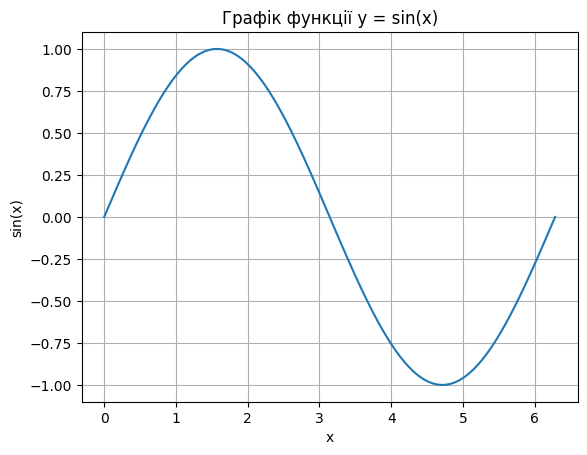

In [33]:
# TODO: xs = np.linspace(0, 2*np.pi, 100), plt.plot(xs, np.sin(xs)), plt.show()
xs = np.linspace(0, 2 * np.pi, 100)
ys = np.sin(xs)

plt.plot(xs, ys)
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("Графік функції y = sin(x)")
plt.grid(True)
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

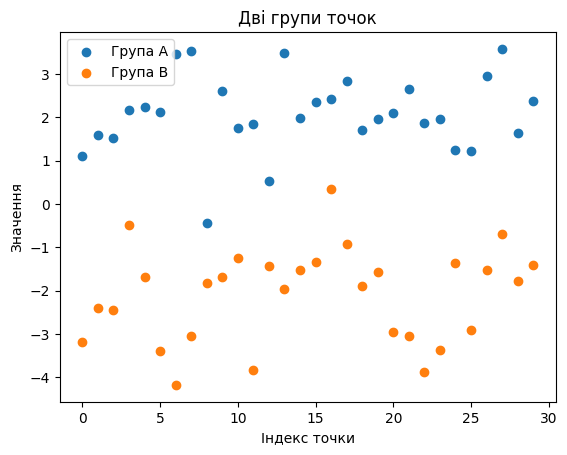

In [34]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),
# додати plt.legend(), plt.show()
plt.scatter(range(len(group_a)), group_a, color="C0", label="Група A")
plt.scatter(range(len(group_b)), group_b, color="C1", label="Група B")

plt.xlabel("Індекс точки")
plt.ylabel("Значення")
plt.title("Дві групи точок")
plt.legend()
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [35]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

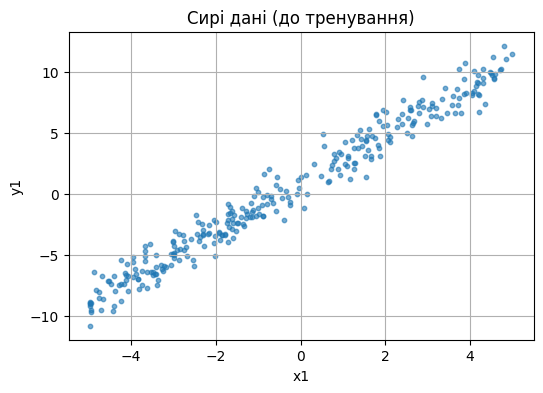

In [36]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.figure(figsize=(6, 4))
plt.scatter(x1.numpy(), y1.numpy(), s=10, alpha=0.6)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.grid(True)
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [37]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
# x_train1, y_train1 = ...
# x_val1, y_val1 = ...
# x_test1, y_test1 = ...
perm = torch.randperm(TASK1_N)

x1_shuffled = x1[perm]
y1_shuffled = y1[perm]

# Обчислюємо межі для 70/15/15
n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)
# залишок йде в test, щоб уникнути втрати точок через округлення
n_test = TASK1_N - n_train - n_val

x_train1, y_train1 = x1_shuffled[:n_train], y1_shuffled[:n_train]
x_val1, y_val1 = x1_shuffled[n_train:n_train + n_val], y1_shuffled[n_train:n_train + n_val]
x_test1, y_test1 = x1_shuffled[n_train + n_val:], y1_shuffled[n_train + n_val:]
print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [38]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


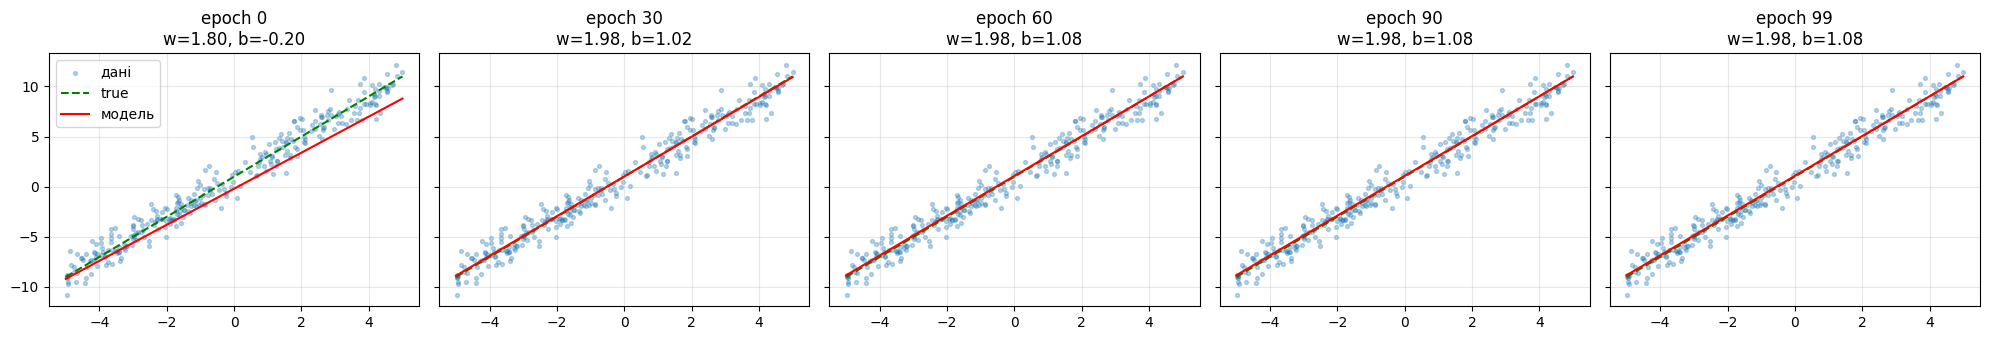

In [39]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Сценарій: стаж роботи → місячна зарплата

Я закладаю таку залежність: **місячна зарплата (тис. грн) лінійно зростає зі стажем роботи (роки)**.

- `w = 15.0` — кожен додатковий рік досвіду в середньому додає **15 тис. грн** до місячної зарплати. Це правдоподібно для сфери на кшталт IT чи інженерії, де досвід відчутно впливає на дохід, особливо на перших 10–15 роках кар'єри.
- `b = 20.0` — базова зарплата **20 тис. грн** для людини без досвіду (стаж = 0), що приблизно відповідає стартовій позиції junior-рівня.
- Стаж (`x`) генерується рівномірно в діапазоні `[0, 15]` років — типовий робочий горизонт від початку кар'єри до досвідченого спеціаліста.
- Шум `ε ~ N(0, σ)` із `σ = 8.0` тис. грн імітує реальний розкид: компанія, регіон, галузь, переговорні навички — усе це вносить варіативність, через яку залежність не ідеально лінійна.

Очікується, що модель, натренована на цих даних, відновить `w ≈ 15` і `b ≈ 20`.


Дані збережено у dataset.csv
   experience_years  salary_thousands
0         13.234039        214.053085
1         13.725060        218.129105
2          5.742956        113.114571
3         14.389585        235.078644
4          5.856723        111.081276


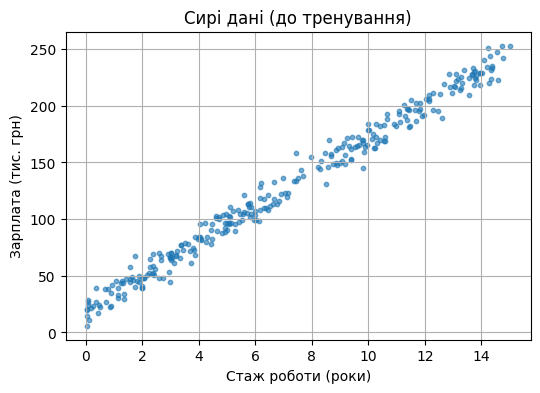


train/val/test: 210/45/45
Epoch  20/200  Train Loss: 152.7006  Val Loss: 115.8477
Epoch  40/200  Train Loss: 136.2212  Val Loss: 101.1508
Epoch  60/200  Train Loss: 122.8094  Val Loss: 89.6054
Epoch  80/200  Train Loss: 111.8942  Val Loss: 80.5840
Epoch 100/200  Train Loss: 103.0109  Val Loss: 73.5802
Epoch 120/200  Train Loss: 95.7812  Val Loss: 68.1852
Epoch 140/200  Train Loss: 89.8974  Val Loss: 64.0697
Epoch 160/200  Train Loss: 85.1088  Val Loss: 60.9687
Epoch 180/200  Train Loss: 81.2117  Val Loss: 58.6689
Epoch 200/200  Train Loss: 78.0400  Val Loss: 56.9993

Істинні параметри:  w = 15.0, b = 20.0
Навчені параметри:  w = 15.7510, b = 14.0386
Test MSE Loss: 61.5893


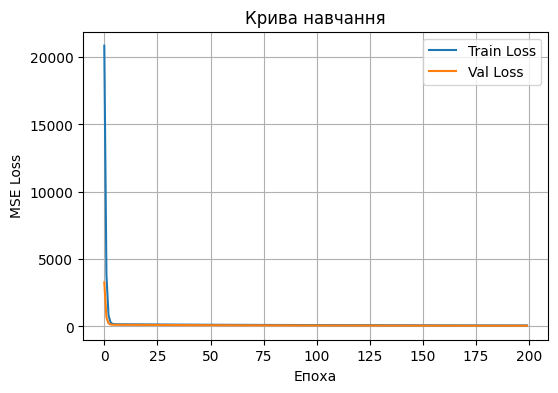

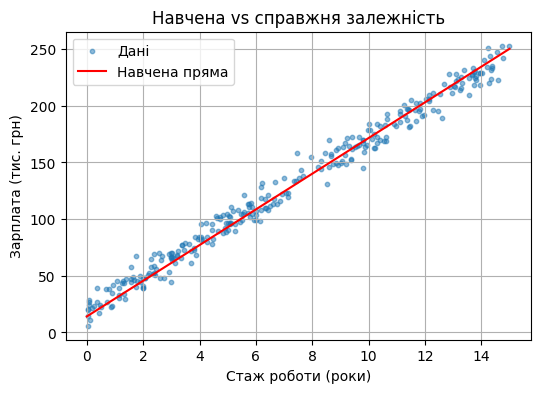

In [40]:
import torch.nn as nn
TASK2_TRUE_W = 15.0
TASK2_TRUE_B = 20.0
TASK2_N = 300
NOISE_STD = 8.0
torch.manual_seed(42)
experience = torch.empty(TASK2_N, 1).uniform_(0, 15)          # стаж, роки
noise2 = NOISE_STD * torch.randn(TASK2_N, 1)
salary = TASK2_TRUE_W * experience + TASK2_TRUE_B + noise2    # зарплата, тис. грн
# --- Збереження у CSV ---
df = pd.DataFrame({
    "experience_years": experience.squeeze().numpy(),
    "salary_thousands": salary.squeeze().numpy()
})
df.to_csv("dataset.csv", index=False)
print("Дані збережено у dataset.csv")
print(df.head())
# --- Погляд на сирі дані ---
plt.figure(figsize=(6, 4))
plt.scatter(experience.numpy(), salary.numpy(), s=10, alpha=0.6)
plt.xlabel("Стаж роботи (роки)")
plt.ylabel("Зарплата (тис. грн)")
plt.title("Сирі дані (до тренування)")
plt.grid(True)
plt.show()

# ==========================================================
# 2. Перевикористовувані функції
# ==========================================================
def train_val_test_split(x, y, train_frac=0.70, val_frac=0.15, seed=0):
    """Перемішує дані і розбиває на train/val/test."""
    n = x.shape[0]
    generator = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=generator)
    x_shuffled, y_shuffled = x[perm], y[perm]
    n_train = int(train_frac * n)
    n_val = int(val_frac * n)
    n_test = n - n_train - n_val
    x_train, y_train = x_shuffled[:n_train], y_shuffled[:n_train]
    x_val, y_val = x_shuffled[n_train:n_train + n_val], y_shuffled[n_train:n_train + n_val]
    x_test, y_test = x_shuffled[n_train + n_val:], y_shuffled[n_train + n_val:]
    return (x_train, y_train), (x_val, y_val), (x_test, y_test)


def train_linear_model(x_train, y_train, x_val, y_val, n_epochs=200, lr=0.01, verbose=True):
    """Тренує nn.Linear(1, 1) через SGD, логуючи train/val loss."""
    model = nn.Linear(in_features=1, out_features=1)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(n_epochs):
        model.train()
        y_pred_train = model(x_train)
        train_loss = loss_fn(y_pred_train, y_train)
        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            y_pred_val = model(x_val)
            val_loss = loss_fn(y_pred_val, y_val)
        history["train_loss"].append(train_loss.item())
        history["val_loss"].append(val_loss.item())
        if verbose and (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch+1:3d}/{n_epochs}  "
                  f"Train Loss: {train_loss.item():.4f}  Val Loss: {val_loss.item():.4f}")
    return model, history

def evaluate_model(model, x_test, y_test):
    """Рахує MSE на test і повертає прогнози."""
    loss_fn = nn.MSELoss()
    model.eval()
    with torch.no_grad():
        y_pred_test = model(x_test)
        test_loss = loss_fn(y_pred_test, y_test)
    return test_loss.item(), y_pred_test

def plot_training_curve(history):
    plt.figure(figsize=(6, 4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Епоха")
    plt.ylabel("MSE Loss")
    plt.title("Крива навчання")
    plt.legend()
    plt.grid(True)
    plt.show()

def plot_fitted_line(model, x, y, x_range=(0, 15)):
    plt.figure(figsize=(6, 4))
    plt.scatter(x.numpy(), y.numpy(), s=10, alpha=0.5, label="Дані")
    xs_line = torch.linspace(*x_range, 100).unsqueeze(1)
    with torch.no_grad():
        ys_line = model(xs_line)
    plt.plot(xs_line.numpy(), ys_line.numpy(), color="red", label="Навчена пряма")
    plt.xlabel("Стаж роботи (роки)")
    plt.ylabel("Зарплата (тис. грн)")
    plt.title("Навчена vs справжня залежність")
    plt.legend()
    plt.grid(True)
    plt.show()
# ==========================================================
# 3. Запуск пайплайну
# ==========================================================
(x_train2, y_train2), (x_val2, y_val2), (x_test2, y_test2) = train_val_test_split(
    experience, salary, train_frac=0.70, val_frac=0.15, seed=0
)

print(f"\ntrain/val/test: {len(x_train2)}/{len(x_val2)}/{len(x_test2)}")

model2, history2 = train_linear_model(
    x_train2, y_train2, x_val2, y_val2, n_epochs=200, lr=0.01
)

test_loss2, y_pred_test2 = evaluate_model(model2, x_test2, y_test2)
learned_w2 = model2.weight.item()
learned_b2 = model2.bias.item()
print(f"\nІстинні параметри:  w = {TASK2_TRUE_W}, b = {TASK2_TRUE_B}")
print(f"Навчені параметри:  w = {learned_w2:.4f}, b = {learned_b2:.4f}")
print(f"Test MSE Loss: {test_loss2:.4f}")
plot_training_curve(history2)
plot_fitted_line(model2, experience, salary, x_range=(0, 15))

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [41]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [42]:
save_dir = "/content/drive/MyDrive"
save_path = os.path.join(save_dir, "model.pt")

torch.save(model2.state_dict(), save_path)

print(f"Модель збережено у: {save_path}")

Модель збережено у: /content/drive/MyDrive/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [43]:
!pip install -q gradio
import gradio as gr

In [44]:
model_path = "/content/drive/MyDrive/model.pt"

loaded_model = nn.Linear(in_features=1, out_features=1)
loaded_model.load_state_dict(torch.load(model_path, map_location="cpu"))
loaded_model.eval()

print("Завантажені параметри:")
print("w:", loaded_model.weight.item())
print("b:", loaded_model.bias.item())
# --- Функція прогнозу ---
def predict_salary(experience_years: float) -> str:
    x = torch.tensor([[experience_years]], dtype=torch.float32)
    with torch.no_grad():
        prediction = loaded_model(x).item()
    return f"Прогнозована зарплата: {prediction:.2f} тис. грн"
# --- Інтерфейс Gradio ---
demo = gr.Interface(
    fn=predict_salary,
    inputs=gr.Slider(minimum=0, maximum=20, step=0.5, value=5, label="Стаж роботи (роки)"),
    outputs=gr.Textbox(label="Прогноз"),
    title="Прогноз зарплати за стажем роботи",
    description=(
        "Лінійна регресія, натренована на синтетичних даних "
        "(salary = w · experience + b + шум). "
        "Введіть стаж роботи, щоб отримати прогнозовану зарплату."
    ),
)

demo.launch(share=True)

Завантажені параметри:
w: 15.751016616821289
b: 14.03862190246582
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4c0e5363f2a423dd89.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```